# Telco Churn Lab

**Ainur Ali**

A reproducible review of customer risk, probability reliability and contact-capacity planning. The training pipeline is implemented in `src/churn_lab/`; this notebook executes the saved experiment and its scoring code rather than repeating model search on every open.

## 1. Load the frozen experiment

Run `python -m churn_lab.cli train` from the repository root to rebuild all outputs. The bundled results use four disjoint partitions: train, calibration, policy and test.

In [1]:
import json

import numpy as np
import pandas as pd
from IPython.display import Image, display

from churn_lab.data import ROOT, feature_frame
from churn_lab.metrics import campaign_plan
from churn_lab.modeling import load_bundle, probabilities

bundle = load_bundle()
manifest = json.loads((ROOT / "artifacts/manifest.json").read_text())
quality = json.loads((ROOT / "reports/data_quality.json").read_text())
print("Champion selected on policy data:", bundle["champion"])
display(pd.DataFrame(quality["splits"]).T)

Champion selected on policy data: catboost_base


,rows,churn_rate
calibration,704.0,0.265625
policy,705.0,0.265248
test,1409.0,0.265436
train,4225.0,0.265325


## 2. Inspect training-only SQL analysis

The query groups contracts and internet services using only training customers. It is descriptive: contract associations do not prove a causal effect.

In [2]:
import duckdb

all_features = pd.read_parquet(ROOT / "reports/features.parquet")
with duckdb.connect() as con:
    con.register("customers", all_features)
    segments = con.execute((ROOT / "sql/segments.sql").read_text()).df()
display(segments.round(3))

,Contract,InternetService,customers,churned,churn_rate,mean_monthly_charge,mean_tenure
0,Month-to-month,Fiber optic,1273,700.0,0.550,87.266,21.764
1,Month-to-month,DSL,723,229.0,0.317,50.293,15.600
2,One year,Fiber optic,336,66.0,0.196,99.125,53.131
3,Month-to-month,No,312,55.0,0.176,20.380,9.128
4,One year,DSL,338,34.0,0.101,61.438,40.509
5,Two year,Fiber optic,259,20.0,0.077,104.433,65.178
6,Two year,DSL,371,8.0,0.022,71.118,59.747
7,One year,No,226,4.0,0.018,20.967,29.518
8,Two year,No,387,5.0,0.013,21.847,48.233


## 3. Compare models on the untouched holdout

AP means average precision. The policy data, not this table, determined the champion. The SQL-feature model is an ablation with the same hyperparameters as the base-feature CatBoost.

,model,roc_auc,average_precision,brier,log_loss,precision,recall,f1,threshold,raw_brier
0,logistic_regression,0.8400,0.6317,0.1388,0.4225,0.5645,0.6551,0.6064,0.38,0.1388
1,catboost_base,0.8447,0.6630,0.1357,0.4166,0.5698,0.6658,0.6141,0.38,0.1357
2,catboost_sql,0.8450,0.6603,0.1357,0.4161,0.5965,0.6364,0.6158,0.41,0.1357
3,constant_baseline,0.5000,0.2654,0.1950,0.5787,0.0000,0.0000,0.0000,0.50,0.1950


,model,fraction,selected,churners_found,precision_at_k,recall_at_k,lift_at_k
1,logistic_regression,0.1,141,103,0.7305,0.2754,2.7521
4,catboost_base,0.1,141,105,0.7447,0.2807,2.8055
7,catboost_sql,0.1,141,106,0.7518,0.2834,2.8322
10,constant_baseline,0.1,141,39,0.2766,0.1043,1.0420
13,monthly_charge_heuristic,0.1,141,36,0.2553,0.0963,0.9619


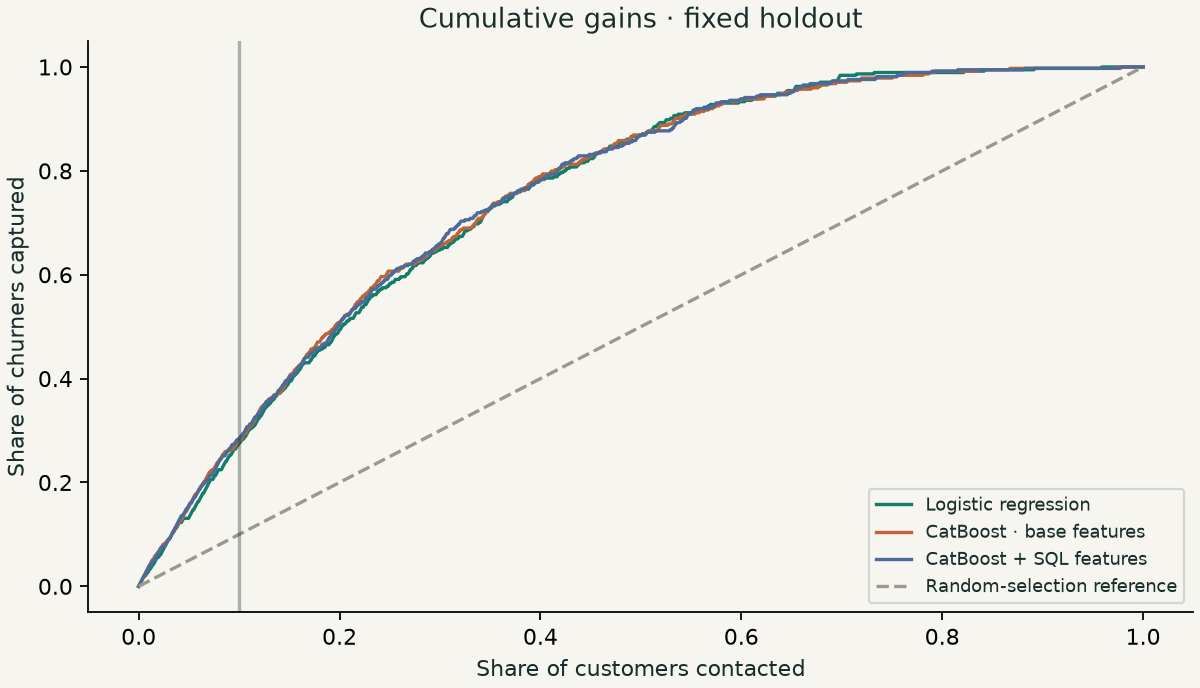

In [3]:
metrics = pd.read_csv(ROOT / "reports/test_metrics.csv")
budgets = pd.read_csv(ROOT / "reports/budget_metrics.csv")
display(metrics.round(4))
display(budgets[np.isclose(budgets.fraction, 0.10)].round(4))
display(Image(filename=str(ROOT / "reports/figures/cumulative_gains.png")))

## 4. Check probability reliability and uncertainty

Calibration was fitted on separate customers. The policy partition chooses whether to use it. Intervals below condition on the fitted models and fixed class proportions; they do not include retraining or temporal drift.

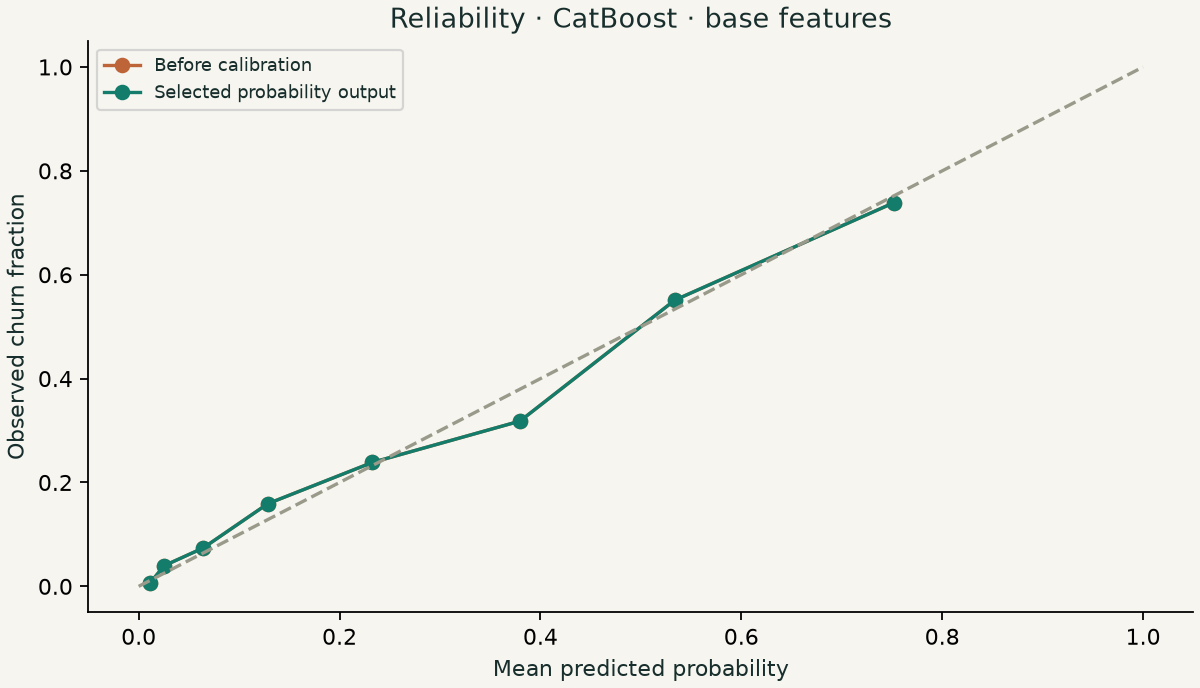

,lower_95,upper_95
roc_auc,0.822771,0.865264
average_precision,0.621148,0.707590
recall_at_10pct,0.256684,0.307487
lift_at_10pct,2.565024,3.072686


{'delta_ap': 0.028607500978488853,
 'ci95': [0.013899067962079842, 0.0419667058617285]}

In [4]:
display(Image(filename=str(ROOT / "reports/figures/calibration.png")))
uncertainty = json.loads((ROOT / "reports/uncertainty.json").read_text())
display(
    pd.DataFrame(uncertainty["per_model"][bundle["champion"]], index=["lower_95", "upper_95"]).T
)
display(uncertainty["catboost_sql_minus_logistic_ap"])

## 5. Score a customer batch with the same SQL

The example contains ten held-out customers, with the label removed. It demonstrates inference and is not a new validation dataset.

In [5]:
raw = pd.read_csv(ROOT / "data/example_customers.csv", dtype=str, keep_default_na=False)
features = feature_frame(raw, training=False)
p = probabilities(bundle, features, bundle["champion"])
display(
    pd.DataFrame(
        {
            "customerID": features.customerID,
            "churn_probability": p,
            "MonthlyCharges": features.MonthlyCharges,
        }
    ).sort_values("churn_probability", ascending=False)
)

,customerID,churn_probability,MonthlyCharges
6,6047-YHPVI,0.673822,69.70
7,5380-WJKOV,0.624566,106.35
9,9420-LOJKX,0.506370,99.10
0,1452-KIOVK,0.447050,89.10
3,5129-JLPIS,0.411231,105.50
1,6713-OKOMC,0.236947,29.75
4,4190-MFLUW,0.154895,55.20
5,6322-HRPFA,0.056278,59.60
2,6388-TABGU,0.035219,56.15
8,2954-PIBKO,0.014509,64.15


## 6. A campaign scenario, not measured retention

The rescue rate is an assumed chance of saving a contacted customer who would otherwise churn. Both contact and incentive costs apply to all contacts. The calculation uses no observed churn labels.

In [6]:
plan, scenario = campaign_plan(
    features,
    p,
    fraction=0.20,
    rescue_rate=0.15,
    horizon=6,
    margin=0.60,
    contact_cost=1,
    incentive_cost=5,
    strategy="expected_value",
    positive_only=True,
)
display(pd.Series(scenario, name="scenario_value"))
display(plan.round(3))

contacted                   2.000000
expected_churners           1.130936
assumed_saved_customers     0.169640
campaign_cost              12.000000
expected_net_value         50.966061
assumed_saved_margin       62.966061
Name: scenario_value, dtype: float64

,priority,customerID,MonthlyCharges,churn_probability,assumed_saved_margin,campaign_cost,expected_net_value
7,1,5380-WJKOV,106.35,0.625,35.868,6,29.868
9,2,9420-LOJKX,99.10,0.506,27.098,6,21.098


## 7. Explain the CatBoost + SQL candidate

SHAP values explain raw log-odds for this specific model. They are not a causal diagnosis or the effect of a proposed offer.

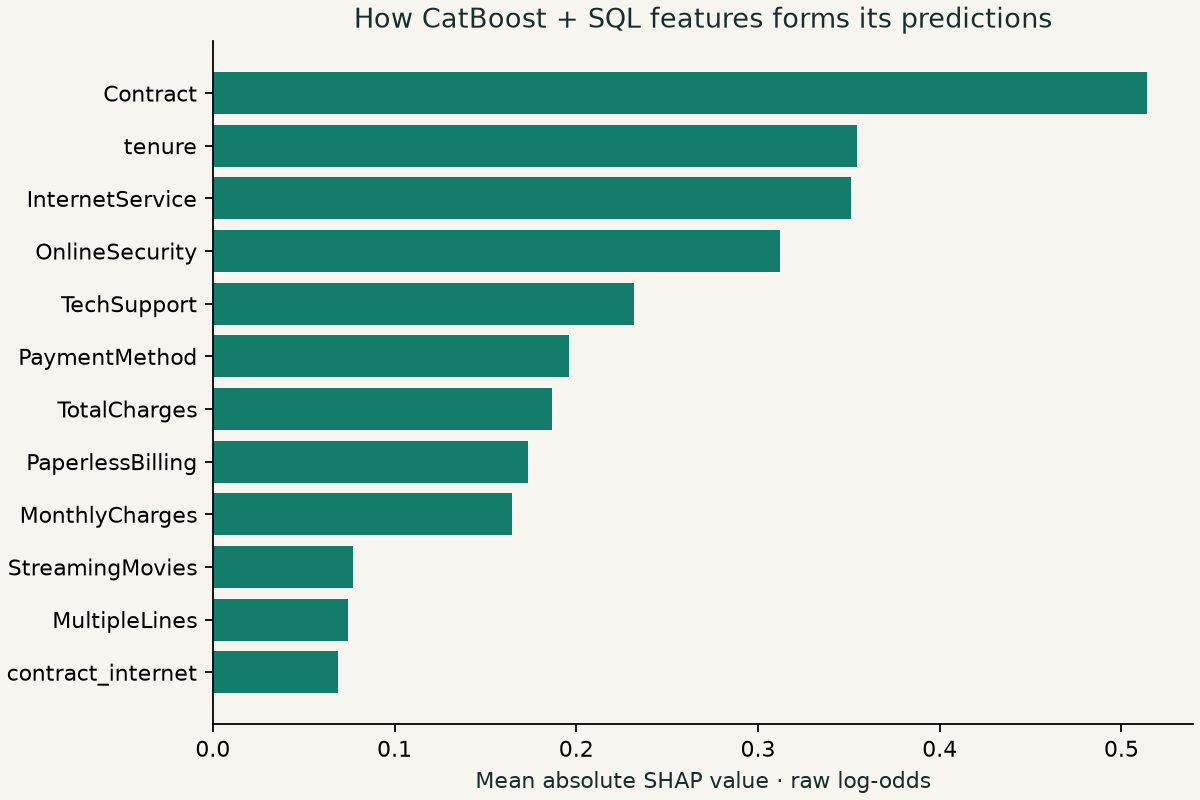

In [7]:
display(Image(filename=str(ROOT / "reports/figures/shap_importance.png")))

## 8. What would come next?

The dataset contains no observation timestamps, event history or treatment/control outcomes. A real continuation needs timestamped features, out-of-time validation and a randomized retention experiment. See `docs/EXPERIMENT_PLAN.md` and `docs/MODEL_CARD.md`.

The additional SQL features did not clearly outperform the base features. Keeping this negative result is part of the comparison; no model is selected by inspecting the final test scores.